# Robustness of metrics to Louvain clustering random seed

In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

import numpy as np
import pandas as pd
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
import glob
import matplotlib.pyplot as plt
import json
import re
import ast
import math
import colorcet as cc
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests
import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')

from analysis_helpers import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [4]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='clustering_random_state', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

In [5]:
ordered_metrics = [
    'MCC', 'F1', 'JACC', 'PURITY', 'HOMO', 'CCENT', # Cluster-as-prediction
    'COMP', # Joint bio&batch
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'CLUSTASW', 'CLUSTCH', 'CLUSTDBI', 'MODULARITY', 'COMPACT', 'SEPARATION', # Independent cluster metrics
    'BATCHARI', 'BCENT', 'BP', "CRE"
]

batch_metrics = ['BATCHARI', 'BCENT', 'BP', 'CRE']

## Collect the data from the eight different datasets

The combined metric file is available as `robustness_louvain_seed.csv`. To reproduce the Kendall's W, instead of using the code to load the CSV files, instead subset the metric file to the given dataset. e.g.

```Python
df_full = pd.read_csv('../data/source_data/robustness_louvain_seed.csv')
df_sub = df_full[df_full['Dataset'] == 'neurips_bmmc']
```


### Human pancreas

In [6]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/human_pancreas/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/human_pancreas_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pancreas_rescue/metrics/all-metrics.csv')
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [7]:
w_results_1 = compute_w_across_integrations(df_sub)
w_results_1['Dataset'] = "human_pancreas"
w_results_1

,Metric,Kendall_W,Dataset
0,AMI,0.997409,human_pancreas
1,ARI,0.996211,human_pancreas
2,AWC,0.996826,human_pancreas
3,BAMI,0.996729,human_pancreas
4,BARI,0.991028,human_pancreas
5,BATCHARI,0.986980,human_pancreas
6,BCENT,0.988130,human_pancreas
7,BP,0.990112,human_pancreas
8,BVM,0.996842,human_pancreas
9,CCENT,0.997409,human_pancreas


In [8]:
df_1 = df_sub.copy()

###  Cellranger versions

In [9]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/cellranger_versions/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/cellranger_versions_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_cellranger_versions_rescue/metrics/all-metrics.csv')
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [10]:
w_results_2 = compute_w_across_integrations(df_sub)
w_results_2['Dataset'] = "cellranger_versions"
w_results_2

,Metric,Kendall_W,Dataset
0,AMI,0.972300,cellranger_versions
1,ARI,0.950676,cellranger_versions
2,AWC,0.951622,cellranger_versions
3,BAMI,0.982474,cellranger_versions
4,BARI,0.982841,cellranger_versions
5,BATCHARI,0.979341,cellranger_versions
6,BCENT,0.968823,cellranger_versions
7,BP,0.968873,cellranger_versions
8,BVM,0.982474,cellranger_versions
9,CCENT,0.984784,cellranger_versions


In [11]:
df_2 = df_sub.copy()

### NeurIPS BMMC

In [12]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/neurips_bmmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_neurips_bmmc/metrics/all-metrics.csv'),
#     pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_neurips_bmmc_rescue/metrics/all-metrics.csv')
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [13]:
w_results_3 = compute_w_across_integrations(df_sub)
w_results_3['Dataset'] = "neurips_bmmc"
w_results_3

,Metric,Kendall_W,Dataset
0,AMI,0.981868,neurips_bmmc
1,ARI,0.916586,neurips_bmmc
2,AWC,0.941337,neurips_bmmc
3,BAMI,0.996169,neurips_bmmc
4,BARI,0.969123,neurips_bmmc
5,BATCHARI,0.965121,neurips_bmmc
6,BCENT,0.962978,neurips_bmmc
7,BP,0.943158,neurips_bmmc
8,BVM,0.996188,neurips_bmmc
9,CCENT,0.993836,neurips_bmmc


In [14]:
df_3 = df_sub.copy()

### scIB sim1

In [15]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/scib_sim1/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/scib_sim1_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_scib_sim1_rescue/metrics/all-metrics.csv')
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [16]:
w_results_4 = compute_w_across_integrations(df_sub)
w_results_4['Dataset'] = "scib_sim1"
w_results_4

,Metric,Kendall_W,Dataset
0,AMI,0.999136,scib_sim1
1,ARI,0.995949,scib_sim1
2,AWC,0.995949,scib_sim1
3,BAMI,0.998392,scib_sim1
4,BARI,0.996545,scib_sim1
5,BATCHARI,0.982429,scib_sim1
6,BCENT,0.998212,scib_sim1
7,BP,0.984918,scib_sim1
8,BVM,0.998392,scib_sim1
9,CCENT,0.999511,scib_sim1


In [17]:
df_4 = df_sub.copy()

### Mouse mammary

In [18]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/mouse_mammary/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/mouse_mammary_rescue/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_mouse_mammary_rescue/metrics/all-metrics.csv')
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [19]:
w_results_5 = compute_w_across_integrations(df_sub)
w_results_5['Dataset'] = "mouse_mammary"
w_results_5

,Metric,Kendall_W,Dataset
0,AMI,0.978785,mouse_mammary
1,ARI,0.978892,mouse_mammary
2,AWC,0.977077,mouse_mammary
3,BAMI,0.974265,mouse_mammary
4,BARI,0.975261,mouse_mammary
5,BATCHARI,0.981206,mouse_mammary
6,BCENT,0.969673,mouse_mammary
7,BP,0.981233,mouse_mammary
8,BVM,0.974265,mouse_mammary
9,CCENT,0.987399,mouse_mammary


In [20]:
df_5 = df_sub.copy()

### Seurat PBMC

In [21]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/seurat_pbmc/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_seurat_pbmc/metrics/all-metrics.csv'),
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [22]:
w_results_6 = compute_w_across_integrations(df_sub)
w_results_6['Dataset'] = "seurat_pbmc"
w_results_6

,Metric,Kendall_W,Dataset
0,AMI,0.954405,seurat_pbmc
1,ARI,0.953058,seurat_pbmc
2,AWC,0.966164,seurat_pbmc
3,BAMI,0.995429,seurat_pbmc
4,BARI,0.987691,seurat_pbmc
5,BATCHARI,0.980161,seurat_pbmc
6,BCENT,0.959734,seurat_pbmc
7,BP,0.961157,seurat_pbmc
8,BVM,0.995448,seurat_pbmc
9,CCENT,0.991275,seurat_pbmc


In [23]:
df_6 = df_sub.copy()

### Human PBMC seq techs

In [24]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/human_pbmc_seq_techs/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_human_pbmc_seq_techs/metrics/all-metrics.csv'),
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()

plt.show()

In [25]:
w_results_7 = compute_w_across_integrations(df_sub)
w_results_7['Dataset'] = "human_pbmc_seq_techs"
w_results_7

,Metric,Kendall_W,Dataset
0,AMI,0.991660,human_pbmc_seq_techs
1,ARI,0.980417,human_pbmc_seq_techs
2,AWC,0.977678,human_pbmc_seq_techs
3,BAMI,0.991803,human_pbmc_seq_techs
4,BARI,0.994233,human_pbmc_seq_techs
5,BATCHARI,0.964891,human_pbmc_seq_techs
6,BCENT,0.977225,human_pbmc_seq_techs
7,BP,0.977665,human_pbmc_seq_techs
8,BVM,0.991680,human_pbmc_seq_techs
9,CCENT,0.996170,human_pbmc_seq_techs


In [26]:
df_7 = df_sub.copy()

### NPH Cerebellum

In [27]:
df = pd.concat([
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/louvain_seed_ablation/nph_cerebellum/metrics/all-metrics.csv'),
    pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/louvain_nph_cerebellum/metrics/all-metrics.csv'),
])


df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[df['Metric'] != 'CLUSTACC']
df = df[~df.Value.isna()]
df_sub = df[df.neighbor_type == 'default']
df_sub = df_sub[df_sub.neighbor_k == 15]
df_sub = df_sub.drop_duplicates(['Integration', 'Metric', 'clustering_random_state'], keep='last')

In [ ]:
label_order = [1, 2, 3, 4, 5]
df_sub['clustering_random_state'] = pd.Categorical(df_sub['clustering_random_state'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'clustering_random_state'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='clustering_random_state',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [28]:
w_results_8 = compute_w_across_integrations(df_sub)
w_results_8['Dataset'] = "nph_cerebellum"
w_results_8

,Metric,Kendall_W,Dataset
0,AMI,0.945323,nph_cerebellum
1,ARI,0.949452,nph_cerebellum
2,AWC,0.940742,nph_cerebellum
3,BAMI,0.966161,nph_cerebellum
4,BARI,0.957935,nph_cerebellum
5,BATCHARI,0.756290,nph_cerebellum
6,BCENT,0.903419,nph_cerebellum
7,BP,0.856840,nph_cerebellum
8,BVM,0.966161,nph_cerebellum
9,CCENT,0.979677,nph_cerebellum


In [29]:
df_8 = df_sub.copy()

## Plot Kendall's W

In [22]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])
w_results = w_results[w_results['Metric'].isin(ordered_metrics)]
w_results.reset_index(drop=True, inplace=True)

/tmp/ipykernel_3127848/2932185574.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


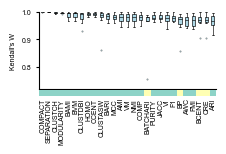

In [23]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import FancyBboxPatch

order = w_results.groupby("Metric")["Kendall_W"].median().sort_values(ascending=False).index
g0 = 'Bioconservation'
g1 = 'Batch correction'
g2 = 'Joint'
metric_to_group = {
    'fmi': g0, 'awc': g0, 'ari': g0, 'vi': g0, 'nmi': g0, 'ami': g0, 'vm':g0, 
    'bari': g0, 'bami': g0, 'bvm': g0, 
    'isoasw': g0, 'gc': g2, 'isof1': g0, 'isolisi': g0,
    'casw': g0, 'cdbi': g0, 'cch': g0, 
    'blogreg': g2, 'flogreg': g0, 
    'clisi': g0, 'fknn': g0, 'ksim': g0, 'ocs': g0, 'nnmap': g0, 'cnent': g0, 
    'cnentropyw': g0, 'bknn': g2, 'f1': g0, 'mcc': g0, 'jacc': g0, 'purity': g0, 
    'ccent': g0, 'homo': g0, 'arif': g0, 'nmif': g0, 
    'clustch': g0, 'clustasw': g0, 'clustdbi': g0, 
    'comp': g0, 'pptpc': g2, 'pstdb': g2, 
    'ldfdiff': g0, 'agree': g0, 'morani': g0, 'rknn': g0, 'ccc': g0, 
    'scgraph': g0, 'corrmse': g0, 'traj': g0, 'scgraphp': g0, 'scgraphm': g0,
    'modularity': g0, 'compact': g0, 'separation': g0,
    'mix': g1, 'align': g1, 'ilisi': g1, 'bnent': g1, 'kldiv': g1,
    'adgbd': g1, 'kbetall': g1, 'cilisi': g1, 'csms': g1, 'kbet': g1,
    'bras': g1, 'embdiv': g1, 'probe': g1, 'batchari': g1, 'pcr': g1,
    'probelr': g1, 'proberf': g1,
    'bp': g1, 'bcent': g1, 'cre': g1,
    'basw': g1, 'sv': g1,
}
group_to_color = {
    g0: '#8dd3c7', g1: '#ffffb3', g2: '#bebada'
}
boxplot_data = [w_results[w_results["Metric"] == metric]["Kendall_W"].values for metric in order]

# 3. Create the boxplot using subplots
fig, ax = plt.subplots(figsize=(2.4, 1.1))

ax.boxplot(
    boxplot_data, 
    labels=order, 
    patch_artist=True,  # Allows filling the boxes with color
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.tick_params(axis='x', length=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylim(0.72, 1)

# 4. Customize labels and layout
ax.set_ylabel("Kendall's W", fontsize=5)
# ax.set_xlabel("Metric", fontsize=5)
# ax.set_title("Distribution of Kendall's W across Datasets by Metric")
ax.set_xticklabels([])

plt.tight_layout()
fig.canvas.draw()  # finalize layout before adding patches

# --- sizing in points ---
box_h_pt   = 4    # height of each color box
box_w_pt   = 18   # width of each color box (adjust to taste)
gap_pt     = 0.6    # gap between tick line and box top

# Convert points to display units
dpi        = fig.dpi
pt_to_disp = dpi / 72.0

# Transform: x in data coords, y pinned to axes bottom in display coords
trans = ax.transData

if len(order) > 1:
    x0_disp = ax.transData.transform((1, ax.get_ylim()[0]))[0]
    x1_disp = ax.transData.transform((2, ax.get_ylim()[0]))[0]
    tick_spacing_disp = x1_disp - x0_disp
else:
    tick_spacing_disp = 20 * pt_to_disp

box_w_disp = tick_spacing_disp * 1  # 85% of spacing, leaving a small gap between boxes

for i, metric in enumerate(order):
    tick_x = i + 1
    grp    = metric_to_group.get(metric.lower(), "Unknown")
    color  = group_to_color.get(grp, "gray")

    x_disp, y_disp = ax.transData.transform((tick_x, ax.get_ylim()[0]))

    box_top    = y_disp - gap_pt * pt_to_disp
    box_bottom = box_top - box_h_pt * pt_to_disp
    box_left   = x_disp - box_w_disp / 2
    box_right  = x_disp + box_w_disp / 2

    inv = ax.transAxes.inverted()
    xl, yt = inv.transform((box_left,  box_top))
    xr, yb = inv.transform((box_right, box_bottom))

    rect = FancyBboxPatch(
        (xl, yb), xr - xl, yt - yb,
        boxstyle="square,pad=0",   # no rounding — boxes are tiny at this scale
        transform=ax.transAxes,
        clip_on=False,
        facecolor=color,
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

    inv = ax.transAxes.inverted()
    lx, ly = inv.transform((x_disp, box_bottom - 2 * pt_to_disp))
    ax.text(
        lx, ly, metric,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=5,
        rotation=90,
        clip_on=False,
    )
# plt.savefig('../publication_figures/louvain_clustering_seed_W.svg', dpi=300, bbox_inches='tight')
plt.show()

In [24]:
df_wide = w_results.pivot_table(index='Dataset', columns='Metric', values="Kendall_W", aggfunc='mean')
pairs = [
    ('BARI', 'ARI'),
    ('BAMI', 'AMI'),
    ('BVM', 'VM')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(61.0), pvalue=np.float64(0.010978693777317534))

In [25]:
df_wide = w_results.pivot_table(index='Dataset', columns='Metric', values="Kendall_W", aggfunc='mean')
pairs = [
    ('AMI', 'ARI'),
    ('BAMI', 'BARI')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(22.0), pvalue=np.float64(0.0155029296875))

In [26]:
w_results.to_csv('../results/spreadsheets/louvain_seed_W.csv')

In [30]:
df_full = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])
df_full = df_full[df_full.Metric != 'ISOF1']

In [31]:
df_full.to_csv('../results/spreadsheets/ablation_analysis_louvain_seed.csv', index=False)